# Manual Backprop

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# pick the GPU if available (on AMD/ROCm builds of PyTorch the GPU is also exposed as 'cuda')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device:', device, f'({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else '')
device = torch.device('cpu')
# Setting it to use CPU as for these small models, cpu is faster than overhead for moving data to GPU

using device: cpu 


In [3]:
import os
data_path = '/content/sample_data/names.txt' if os.path.exists('/content/sample_data/names.txt') else 'names.txt'  # Colab or local
words = open(data_path).read().splitlines()

In [4]:
print(len(words))
print(max(len(w) for w in words))
print(words[:8])

32033
15
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']


In [5]:
# build vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(stoi)
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [6]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]    # crop and append

    X = torch.tensor(X, device=device)
    Y = torch.tensor(Y, device=device)
    print(X.shape, Y.shape)
    return X, Y

In [7]:
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])            # 80%
Xdev, Ydev = build_dataset(words[n1:n2])        # 10%
Xte, Yte = build_dataset(words[n2:])            # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [8]:
# ok biolerplate done, now we get to the action:

In [9]:
# utility function we will use later when comparing manual gradients to PyTorch gradients
def cmp(s, dt, t):
  ex = torch.all(dt == t.grad).item()
  app = torch.allclose(dt, t.grad)
  maxdiff = (dt - t.grad).abs().max().item()
  print(f'{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

In [10]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 64   # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
# Layer 1
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)      # [30, 64]
b1 = torch.randn(n_hidden,                        generator=g) * 0.1 # using b1 just for fun, it's useless because of BN    # [64,] -> braoadcasted to [32, 64]
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.1 #[64, 27]
b2 = torch.randn(vocab_size,                        generator=g) * 0.1 #[27,] broadcasted to [32, 27]

# Batch Norm Parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0   # [1, 64]
bnbias = torch.randn((1, n_hidden))*0.1         # [1, 64]

bnmean_running = torch.zeros((1, n_hidden))     # [1, 64]
bnstd_running = torch.ones((1, n_hidden))       # [1, 64]

# Note: I am initializating many of these parameters in non-standard ways
# because sometimes initializating with e.g. all zeros could mask an incorrect
# implementation of the backward pass.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

4137


In [11]:
batch_size = 32
m = batch_size # a shorter variable name, for convinience

ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # Create an array of size (32,) by picking 32 random integers between 0 and 180k (Xtr.shape[0])
Xb, Yb = Xtr[ix], Ytr[ix] # Xb -> [32, 3]

In [12]:
# forward pass, "chunkated" into smaller steps that are possoble to backward one at a time

emb = C[Xb]             # [32, 3, 10]
embcat = emb.view(emb.shape[0], -1) # [32, 30] -> concatenate the vectors

# ----------------- Linear Layer 1 ---------------------
hprebn = embcat @ W1 + b1 # [32, 64] -> hidden layer pre batch-norm

# ----------------- BatchNorm Layer --------------------
bnmean = 1/m * hprebn.sum(dim = 0, keepdims=True) # [1, 64] -> The mean across 32 examples of this batch
bndiff = hprebn - bnmean # [32, 64] - [1, 64] = [32, 64], bnmean broadcasted to all 32 examples.
bndiff2 = bndiff**2         # [32, 64]
bnvar = 1/(m-1)* bndiff2.sum(dim=0, keepdims=True) # note: Bessel's correction, (dividing by m-1, not m)    [1, 64], summed over 32 rows

bnvar_inv = (bnvar + 1e-5)**-0.5    # [1, 64]
bnraw = bndiff * bnvar_inv          # [32, 64] - bnvar_inv is broadcasted
hpreact = bngain * bnraw + bnbias   # [32, 64]

# ------------------ Non Linearity --------------------

h = torch.tanh(hpreact)         # [32, 64]

# ----------------- Linear Layer 2 ---------------------
logits = h @ W2 + b2            # [32, 64] @ [64, 27] = [32, 27]

# ----------------- Cross Entropy Loss -----------------

logit_maxes = logits.max(dim=1, keepdim=True).values # [32, 1] -> find max value of logit in each example. Eah example has a output porbability distribution over the 27 charcaters. We pick the max one -> for cross entropy normalizaition. Otherwise e^zi can overflow to inf. So we need to do e^(z_i-z_max)
norm_logits = logits - logit_maxes    # [32, 27], logit_maxes is broadcasted
counts = norm_logits.exp()         # [32, 27]
counts_sum = counts.sum(dim=1, keepdim=True) # [32, 1]
counts_sum_inv = counts_sum**-1    # [32, 1] -> 1/summation(z_j)

probs = counts * counts_sum_inv     # [32, 27], sum_inv is broadcasted
logprobs = probs.log()              # [32, 27]
loss = -logprobs[range(m), Yb].mean()   # [1],  mean() takes[32, 1] to [1]


intermediate_vars = [logprobs, probs, counts, counts_sum, counts_sum_inv, norm_logits, logit_maxes, logits, h, hpreact, bnraw, bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmean, embcat, emb]

# PyTorch backward pass
for p in parameters:
    p.grad = None
# there is no cleaner way to retain gradients, other than the one below.

for t in intermediate_vars:
    t.retain_grad()
loss.backward()
loss

tensor(3.3439, grad_fn=<NegBackward0>)

In [13]:
# Exercise 1: backprop through the whole thing manually,
# backpropagating through exactly all of the variables
# as they are defined in the forward pass above, one by one

# -----------------
# YOUR CODE HERE :)
# -----------------
dlogprobs = torch.zeros_like(logprobs)      # [32, 27]
dlogprobs[range(m), Yb] = -1.0/m            # [32, 27]
dprobs = 1/probs * dlogprobs                  # [32, 27]
dcounts_sum_inv = (counts*dprobs).sum(dim=1, keepdim=True) # [32, 1]
dcounts_sum = -1* (counts_sum)**-2 * dcounts_sum_inv # [32, 1]
dcounts = dcounts_sum + counts_sum_inv*dprobs # [32, 27]
dnorm_logits = counts*dcounts               # [32, 27]
dlogit_maxes = -dnorm_logits.sum(dim=1, keepdim=True) # [32, 1]

dlogits_intermediate = torch.zeros_like(logits)   # [32, 27]
dlogits_intermediate[range(m), logits.max(dim=1).indices] = 1 # [32, 27]
dlogits = dnorm_logits + dlogits_intermediate * dlogit_maxes     # [32, 27]

# dlogits = dnorm_logits + F.one_hot(logits.max(dim=1).indices, num_classes=vocab_size) * dlogit_maxes      # [32, 27]

dh = dlogits @ W2.T                         # [32, 64]
dW2 = h.T @ dlogits                         # [64, 27]
db2 = dlogits.sum(dim=0, keepdim=True)      # [ 1, 27]

dhpreact = (1.0 - h**2)*dh                  # [32, 64]
dbngain = (bnraw * dhpreact).sum(dim=0, keepdim=True) # [1, 64]
dbnbias = dhpreact.sum(dim=0, keepdim=True) # [ 1, 64]
dbnraw = bngain * dhpreact                  # [32, 64]
dbnvar_inv = (bndiff * dbnraw).sum(dim=0, keepdim=True) # [1, 64]
dbnvar = -0.5* (bnvar + 1e-5)**-1.5 * dbnvar_inv # [1 ,64]
dbndiff2= 1/(m-1) * dbnvar.expand(batch_size, -1)# [32, 64]
dbndiff = 2 * bndiff * dbndiff2 + dbnraw * bnvar_inv # [32, 64]
dbnmean = -dbndiff.sum(dim=0, keepdim =True)         # [1, 64]
dhprebn = dbndiff + (1/m)*dbnmean.expand(batch_size, -1) # [32, 64]
dembcat = dhprebn @ W1.T                    # [32, 30]
dW1 = embcat.T @ dhprebn                    # [30, 64]
db1 = dhprebn.sum(dim=0)                    # [64,]
demb = dembcat.view(emb.shape[0], block_size, -1) # [32, 3, 10]
dC = torch.zeros_like(C)

for k in range(Xb.shape[0]):
    for j in range(Xb.shape[1]):
        ix = Xb[k,j] # X is an 2D array of token_integers. We pick out each token integer from x and get the token ineger value. Then we go to demb, pick out the server rack from that poistion in demb and deposit (because we are doing +=) in the correct index of token integer.
        dC[ix] += demb[k,j]

cmp('logprobs', dlogprobs, logprobs)
cmp('probs', dprobs, probs)
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)
cmp('counts_sum', dcounts_sum, counts_sum)
cmp('counts', dcounts, counts)
cmp('norm_logits', dnorm_logits, norm_logits)
cmp('logit_maxes', dlogit_maxes, logit_maxes)
cmp('logits', dlogits, logits)
cmp('h', dh, h)
cmp('W2', dW2, W2)
cmp('b2', db2, b2)
cmp('hpreact', dhpreact, hpreact)
cmp('bngain', dbngain, bngain)
cmp('bnbias', dbnbias, bnbias)
cmp('bnraw', dbnraw, bnraw)
cmp('bnvar_inv', dbnvar_inv, bnvar_inv)
cmp('bnvar', dbnvar, bnvar)
cmp('bndiff2', dbndiff2, bndiff2)
cmp('bndiff', dbndiff, bndiff)
cmp('bnmean', dbnmean, bnmean)
cmp('hprebn', dhprebn, hprebn)
cmp('embcat', dembcat, embcat)
cmp('W1', dW1, W1)
cmp('b1', db1, b1)
cmp('emb', demb, emb)
cmp('C', dC, C)

logprobs        | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum      | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0
logit_maxes     | exact: True  | approximate: True  | maxdiff: 0.0
logits          | exact: True  | approximate: True  | maxdiff: 0.0
h               | exact: True  | approximate: True  | maxdiff: 0.0
W2              | exact: True  | approximate: True  | maxdiff: 0.0
b2              | exact: True  | approximate: True  | maxdiff: 0.0
hpreact         | exact: True  | approximate: True  | maxdiff: 0.0
bngain          | exact: True  | approximate: True  | maxdiff: 0.0
bnbias          | exact: True  | approximate: True  | maxdiff: 0.0
bnraw           | exact: True  | approximate: True  | maxdiff:

In [14]:
# Exercise 2: backprop through cross_entropy but all in one go
# to complete this challenge, look at the mathematical expression of the loss,
# take the derivative, simplify the expression, and just write it out.

# forward pass

# before:
# logits = h @ W2 + b2            # [32, 27]
# logit_maxes = logits.max(1, keepdim=True).values # [32, 1]
# norm_logits = logits - logit_maxes # [32, 27]
# counts = norm_logits.exp()  # [32, 27]
# count_sum = counts.sum(dim=1, keepdim = True) # [32, 1]
# counts_sum_inv = counts_sum**-1.0       # [32, 1]

# probs = counts * counts_sum_inv
# logprobs = probs.log()
# loss = -logprobs[range(m), Yb].mean()

# now
loss_fast = F.cross_entropy(logits, Yb)
print(loss_fast.item(), 'diff:', (loss_fast - loss).item())

3.3439321517944336 diff: 0.0


In [15]:
# backward pass

dlogits = 1/m*(F.softmax(logits, dim=1) - F.one_hot(Yb, num_classes=vocab_size))

cmp('logits', dlogits, logits) # I can only get approximate to be true, my maxdiff is 6e-9

logits          | exact: False | approximate: True  | maxdiff: 7.450580596923828e-09


In [16]:
print(F.softmax(logits, dim=1)[0])
print(dlogits[0] * m)

tensor([0.0734, 0.0935, 0.0176, 0.0485, 0.0197, 0.0797, 0.0263, 0.0321, 0.0173,
        0.0331, 0.0382, 0.0365, 0.0345, 0.0288, 0.0334, 0.0132, 0.0088, 0.0198,
        0.0155, 0.0521, 0.0509, 0.0211, 0.0248, 0.0723, 0.0595, 0.0282, 0.0214],
       grad_fn=<SelectBackward0>)
tensor([ 0.0734,  0.0935,  0.0176,  0.0485,  0.0197,  0.0797,  0.0263,  0.0321,
        -0.9827,  0.0331,  0.0382,  0.0365,  0.0345,  0.0288,  0.0334,  0.0132,
         0.0088,  0.0198,  0.0155,  0.0521,  0.0509,  0.0211,  0.0248,  0.0723,
         0.0595,  0.0282,  0.0214], grad_fn=<MulBackward0>)


In [17]:
print(dlogits.shape)
print(dlogits[0])

torch.Size([32, 27])
tensor([ 0.0023,  0.0029,  0.0006,  0.0015,  0.0006,  0.0025,  0.0008,  0.0010,
        -0.0307,  0.0010,  0.0012,  0.0011,  0.0011,  0.0009,  0.0010,  0.0004,
         0.0003,  0.0006,  0.0005,  0.0016,  0.0016,  0.0007,  0.0008,  0.0023,
         0.0019,  0.0009,  0.0007], grad_fn=<SelectBackward0>)


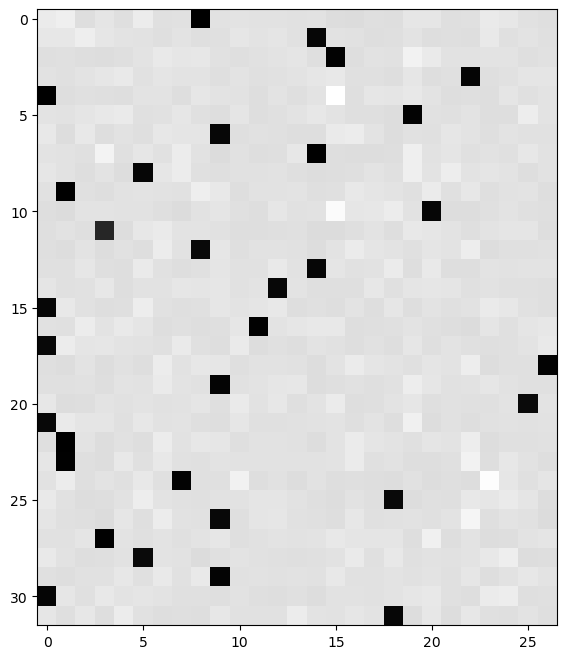

In [18]:
plt.figure(figsize=(8,8))
plt.imshow(dlogits.detach(), cmap='grey')

In [19]:
# Exercise 3: backprop through batchnorm but all in one go.
# to complete this challenge look at the mathematical expression of
# the output of batchnorm, take the derivative wrt its input,
# simplify the expression and just write it out.

# forward pass

# before:
# hprebn = embcat @ W1 + b1
# bnmean = hprebn.mean(dim=0, keepdim=True)
# bdiff = hprebn - bnmean
# bndiff2 = bndiff**2
# bnvar = 1/(m-1)* bndiff2.sum(dim=0, keepdim=True)
# bnvar_inv = (bnvar + 1e-5)**-0.5
# bnraw = bndiff * bnvar_inv
# hpreact = bngain * bnraw + bnbias

# now:
hpreact_fast = bngain * (hprebn - hprebn.mean(0, keepdim=True))/torch.sqrt(hprebn.var(0, keepdim=True, unbiased=True) + 1e-5) + bnbias
print('max diff:', (hpreact_fast- hpreact).abs().max())

max diff: tensor(7.1526e-07, grad_fn=<MaxBackward1>)


In [20]:
# backward pass

# before we had:
# dhpreact = (1.0 - h**2)*dh                  # [32, 64]
# dbngain = (bnraw * dhpreact).sum(dim=0, keepdim=True) # [1, 64]
# dbnbias = dhpreact.sum(dim=0, keepdim=True) # [ 1, 64]
# dbnraw = bngain * dhpreact                  # [32, 64]
# dbnvar_inv = (bndiff * dbnraw).sum(dim=0, keepdim=True) # [1, 64]
# dbnvar = -0.5* (bnvar + 1e-5)**-1.5 * dbnvar_inv # [1 ,64]
# dbndiff2= 1/(m-1) * dbnvar.expand(batch_size, -1)# [32, 64]
# dbndiff = 2 * bndiff * dbndiff2 + dbnraw * bnvar_inv # [32, 64]
# dbnmean = -dbndiff.sum(dim=0, keepdim =True)         # [1, 64]
# dhprebn = dbndiff + (1/m)*dbnmean.expand(batch_size, -1) # [32, 64]

In [21]:
# calculate dhprebn given dhpreact (i.e., backprop through the batchnorm)
# (you'll also need to use some of the variables from the forward pass above)

# -----------------
# YOUR CODE HERE :)
dhprebn = (1/m) * bngain * bnvar_inv * (m*dhpreact - dhpreact.sum(0, keepdim=True) - (m/(m-1))* bnraw * (dhpreact*bnraw).sum(0,keepdim=True))
# -----------------

cmp('hprebn', dhprebn, hprebn)

hprebn          | exact: False | approximate: True  | maxdiff: 9.313225746154785e-10


# Exercise 4: putting it all together!
Train the MLP neural net with your own backward pass

### 1. First with loss.backward() - cross entropy formula is detailed

In [25]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200   # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
# Layer 1
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)      # [30, 200]
b1 = torch.randn(n_hidden,                        generator=g) * 0.1 # using b1 just for fun, it's useless because of BN    # [200,] -> braoadcasted to [32, 200]
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.1 #[200, 27]
b2 = torch.randn(vocab_size,                        generator=g) * 0.1 #[27,] broadcasted to [32, 27]

# Batch Norm Parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0   # [1, 200]
bnbias = torch.randn((1, n_hidden))*0.1         # [1, 200]

bnmean_running = torch.zeros((1, n_hidden))     # [1, 200]
bnstd_running = torch.ones((1, n_hidden))       # [1, 200]

# Note: I am initializating many of these parameters in non-standard ways
# because sometimes initializating with e.g. all zeros could mask an incorrect
# implementation of the backward pass.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [26]:
max_steps = 200000
batch_size = 32
m = batch_size # a shorter variable name, for convinience
lossi = []

In [27]:
# use this context manager for efficiency once your backward pass is written (TODO)
#with torch.no_grad():

# kick off optimization
for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # Create an array of size (32,) by picking 32 random integers between 0 and 180k (Xtr.shape[0])
    Xb, Yb = Xtr[ix], Ytr[ix] # Xb -> [32, 3]

    emb = C[Xb]             # [32, 3, 10]
    embcat = emb.view(emb.shape[0], -1) # [32, 30] -> concatenate the vectors

    # ----------------- Linear Layer 1 ---------------------
    hprebn = embcat @ W1 + b1 # [32, 64] -> hidden layer pre batch-norm

    # ----------------- BatchNorm Layer --------------------
    bnmean = 1/m * hprebn.sum(dim = 0, keepdims=True) # [1, 64] -> The mean across 32 examples of this batch
    bndiff = hprebn - bnmean # [32, 64] - [1, 64] = [32, 64], bnmean broadcasted to all 32 examples.
    bndiff2 = bndiff**2         # [32, 64]
    bnvar = 1/(m-1)* bndiff2.sum(dim=0, keepdims=True) # note: Bessel's correction, (dividing by m-1, not m)    [1, 64], summed over 32 rows

    bnvar_inv = (bnvar + 1e-5)**-0.5    # [1, 64]
    bnraw = bndiff * bnvar_inv          # [32, 64] - bnvar_inv is broadcasted
    hpreact = bngain * bnraw + bnbias   # [32, 64]

    # ------------------ Non Linearity --------------------

    h = torch.tanh(hpreact)         # [32, 64]

    # ----------------- Linear Layer 2 ---------------------
    logits = h @ W2 + b2            # [32, 64] @ [64, 27] = [32, 27]

    # ----------------- Cross Entropy Loss -----------------

    logit_maxes = logits.max(dim=1, keepdim=True).values # [32, 1] -> find max value of logit in each example. Eah example has a output porbability distribution over the 27 charcaters. We pick the max one -> for cross entropy normalizaition. Otherwise e^zi can overflow to inf. So we need to do e^(z_i-z_max)
    norm_logits = logits - logit_maxes    # [32, 27], logit_maxes is broadcasted
    counts = norm_logits.exp()         # [32, 27]
    counts_sum = counts.sum(dim=1, keepdim=True) # [32, 1]
    counts_sum_inv = counts_sum**-1    # [32, 1] -> 1/summation(z_j)

    probs = counts * counts_sum_inv     # [32, 27], sum_inv is broadcasted
    logprobs = probs.log()              # [32, 27]
    loss = -logprobs[range(m), Yb].mean()   # [1],  mean() takes[32, 1] to [1]


    intermediate_vars = [logprobs, probs, counts, counts_sum, counts_sum_inv, norm_logits, logit_maxes, logits, h, hpreact, bnraw, bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmean, embcat, emb]

    # PyTorch backward pass
    for p in parameters:
        p.grad = None
    # there is no cleaner way to retain gradients, other than the one below.

    for t in intermediate_vars:
        t.retain_grad()
    loss.backward() # use this for correctness comparisons, delete it later!

    # manual backprop! #swole_doge_meme
    # -----------------
    # YOUR CODE HERE :)
    dC, dW1, db1, dW2, db2, dbngain, dbnbias = None, None, None, None, None, None, None
    grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]
    # -----------------

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p, grad in zip(parameters, grads):
        p.data += -lr * p.grad # old way of cheems doge (using PyTorch grad from .backward())
        #p.data += -lr * grad # new way of swole doge TODO: enable
    
    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 200000: 3.7968
  10000/ 200000: 2.1518
  20000/ 200000: 2.4067
  30000/ 200000: 2.4292
  40000/ 200000: 1.9992
  50000/ 200000: 2.3653
  60000/ 200000: 2.4144
  70000/ 200000: 2.0552
  80000/ 200000: 2.3512
  90000/ 200000: 2.1540
 100000/ 200000: 1.9410
 110000/ 200000: 2.3598
 120000/ 200000: 1.9228
 130000/ 200000: 2.4501
 140000/ 200000: 2.2893
 150000/ 200000: 2.1879
 160000/ 200000: 1.9905
 170000/ 200000: 1.8305
 180000/ 200000: 2.0515
 190000/ 200000: 1.9510


In [28]:
# useful for checking your gradients
# for p,g in zip(parameters, grads):
#   cmp(str(tuple(p.shape)), g, p)

In [ ]:
# calibrate the batch norm at the end of training

with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnvar = hpreact.var(0, keepdim=True, unbiased=True)

In [30]:
# evaluate train and val loss

@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0719354152679443
val 2.1103451251983643


In [ ]:
# Using loss.backward()
# train 2.0719354152679443
# val 2.1103451251983643

In [31]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass
      emb = C[torch.tensor([context])] # (1,block_size,d)      
      embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
      hpreact = embcat @ W1 + b1
      hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
      h = torch.tanh(hpreact) # (N, n_hidden)
      logits = h @ W2 + b2 # (N, vocab_size)
      # sample
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carlaizabelle.
khylmir.
reity.
sacarlie.
mahnen.
delynn.
jareen.
nellara.
chaiivon.
leigh.
ham.
joce.
quinn.
salin.
alianni.
waythoniearisia.
kael.
dura.
med.
edi.


### 2. Using F.cross_entopry but still loss.backward()

In [24]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200   # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
# Layer 1
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)      # [30, 200]
b1 = torch.randn(n_hidden,                        generator=g) * 0.1 # using b1 just for fun, it's useless because of BN    # [200,] -> braoadcasted to [32, 200]
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.1 #[200, 27]
b2 = torch.randn(vocab_size,                        generator=g) * 0.1 #[27,] broadcasted to [32, 27]

# Batch Norm Parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0   # [1, 200]
bnbias = torch.randn((1, n_hidden))*0.1         # [1, 200]

bnmean_running = torch.zeros((1, n_hidden))     # [1, 200]
bnstd_running = torch.ones((1, n_hidden))       # [1, 200]

# Note: I am initializating many of these parameters in non-standard ways
# because sometimes initializating with e.g. all zeros could mask an incorrect
# implementation of the backward pass.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [25]:
max_steps = 200000
batch_size = 32
m = batch_size # a shorter variable name, for convinience
lossi = []

In [26]:
# use this context manager for efficiency once your backward pass is written (TODO)
#with torch.no_grad():

# kick off optimization
for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # Create an array of size (32,) by picking 32 random integers between 0 and 180k (Xtr.shape[0])
    Xb, Yb = Xtr[ix], Ytr[ix] # Xb -> [32, 3]

    emb = C[Xb]             # [32, 3, 10]
    embcat = emb.view(emb.shape[0], -1) # [32, 30] -> concatenate the vectors

    # ----------------- Linear Layer 1 ---------------------
    hprebn = embcat @ W1 + b1 # [32, 64] -> hidden layer pre batch-norm

    # ----------------- BatchNorm Layer --------------------
    bnmean = 1/m * hprebn.sum(dim = 0, keepdims=True) # [1, 64] -> The mean across 32 examples of this batch
    bndiff = hprebn - bnmean # [32, 64] - [1, 64] = [32, 64], bnmean broadcasted to all 32 examples.
    bndiff2 = bndiff**2         # [32, 64]
    bnvar = 1/(m-1)* bndiff2.sum(dim=0, keepdims=True) # note: Bessel's correction, (dividing by m-1, not m)    [1, 64], summed over 32 rows

    bnvar_inv = (bnvar + 1e-5)**-0.5    # [1, 64]
    bnraw = bndiff * bnvar_inv          # [32, 64] - bnvar_inv is broadcasted
    hpreact = bngain * bnraw + bnbias   # [32, 64]

    # ------------------ Non Linearity --------------------

    h = torch.tanh(hpreact)         # [32, 64]

    # ----------------- Linear Layer 2 ---------------------
    logits = h @ W2 + b2            # [32, 64] @ [64, 27] = [32, 27]

    # ----------------- Cross Entropy Loss -----------------
    loss = F.cross_entropy(logits, Yb)  # loss Function

    intermediate_vars = [logprobs, probs, counts, counts_sum, counts_sum_inv, norm_logits, logit_maxes, logits, h, hpreact, bnraw, bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmean, embcat, emb]

    # PyTorch backward pass
    for p in parameters:
        p.grad = None
    # there is no cleaner way to retain gradients, other than the one below.

    for t in intermediate_vars:
        t.retain_grad()
    loss.backward() # use this for correctness comparisons, delete it later!

    # manual backprop! #swole_doge_meme
    # -----------------
    # YOUR CODE HERE :)
    dC, dW1, db1, dW2, db2, dbngain, dbnbias = None, None, None, None, None, None, None
    grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]
    # -----------------

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p, grad in zip(parameters, grads):
        p.data += -lr * p.grad # old way of cheems doge (using PyTorch grad from .backward())
        #p.data += -lr * grad # new way of swole doge TODO: enable
    
    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 200000: 3.7563
  10000/ 200000: 2.1666
  20000/ 200000: 2.3967
  30000/ 200000: 2.4969
  40000/ 200000: 2.0059
  50000/ 200000: 2.4002
  60000/ 200000: 2.3520
  70000/ 200000: 1.9992
  80000/ 200000: 2.3134
  90000/ 200000: 2.0633
 100000/ 200000: 1.9267
 110000/ 200000: 2.4035
 120000/ 200000: 2.0040
 130000/ 200000: 2.5139
 140000/ 200000: 2.2689
 150000/ 200000: 2.1946
 160000/ 200000: 2.0174
 170000/ 200000: 1.7720
 180000/ 200000: 2.0242
 190000/ 200000: 1.8793


In [27]:
# calibrate the batch norm at the end of training

with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnvar = hpreact.var(0, keepdim=True, unbiased=True)

In [28]:
# evaluate train and val loss

@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.072214126586914
val 2.11366605758667


In [ ]:
# F.cross_entropy and loss.backward()
# train 2.072214126586914
# val 2.11366605758667

## Now with Maximal Detailed Version of Backprop (after exercise 1)

In [35]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200   # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
# Layer 1
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)      # [30, 200]
b1 = torch.randn((1, n_hidden),                     generator=g) * 0.1 # [1, 200] -> broadcast to [32, 200]
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.1 # [200, 27]
b2 = torch.randn((1, vocab_size),                   generator=g) * 0.1 # [1, 27]  -> broadcast to [32, 27]

# Batch Norm Parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0   # [1, 200]
bnbias = torch.randn((1, n_hidden))*0.1         # [1, 200]

bnmean_running = torch.zeros((1, n_hidden))     # [1, 200]
bnstd_running = torch.ones((1, n_hidden))       # [1, 200]

# Note: I am initializating many of these parameters in non-standard ways
# because sometimes initializating with e.g. all zeros could mask an incorrect
# implementation of the backward pass.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [36]:
max_steps = 200000
batch_size = 32
m = batch_size # a shorter variable name, for convinience
lossi = []

In [40]:
# use this context manager for efficiency once your backward pass is written (TODO)
#with torch.no_grad():

# kick off optimization
for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # Create an array of size (32,) by picking 32 random integers between 0 and 180k (Xtr.shape[0])
    Xb, Yb = Xtr[ix], Ytr[ix] # Xb -> [32, 3]

    emb = C[Xb]             # [32, 3, 10]
    embcat = emb.view(emb.shape[0], -1) # [32, 30] -> concatenate the vectors

    # ----------------- Linear Layer 1 ---------------------
    hprebn = embcat @ W1 + b1 # [32, 200] -> hidden layer pre batch-norm

    # ----------------- BatchNorm Layer --------------------
    bnmean = 1/m * hprebn.sum(dim = 0, keepdims=True) # [1, 200] -> The mean across 32 examples of this batch
    bndiff = hprebn - bnmean # [32, 200] - [1, 200] = [32, 200], bnmean broadcasted to all 32 examples.
    bndiff2 = bndiff**2         # [32, 200]
    bnvar = 1/(m-1)* bndiff2.sum(dim=0, keepdims=True) # note: Bessel's correction, (dividing by m-1, not m)    [1, 200], summed over 32 rows

    bnvar_inv = (bnvar + 1e-5)**-0.5    # [1, 200]
    bnraw = bndiff * bnvar_inv          # [32, 200] - bnvar_inv is broadcasted
    hpreact = bngain * bnraw + bnbias   # [32, 200]

    # ------------------ Non Linearity --------------------

    h = torch.tanh(hpreact)         # [32, 200]

    # ----------------- Linear Layer 2 ---------------------
    logits = h @ W2 + b2            # [32, 200] @ [200, 27] = [32, 27]

    # ----------------- Cross Entropy Loss -----------------
    logit_maxes = logits.max(dim=1, keepdim=True).values # [32, 1] -> find max value of logit in each example. Eah example has a output porbability distribution over the 27 charcaters. We pick the max one -> for cross entropy normalizaition. Otherwise e^zi can overflow to inf. So we need to do e^(z_i-z_max)
    norm_logits = logits - logit_maxes    # [32, 27], logit_maxes is broadcasted
    counts = norm_logits.exp()         # [32, 27]
    counts_sum = counts.sum(dim=1, keepdim=True) # [32, 1]
    counts_sum_inv = counts_sum**-1    # [32, 1] -> 1/summation(z_j)

    probs = counts * counts_sum_inv     # [32, 27], sum_inv is broadcasted
    logprobs = probs.log()              # [32, 27]
    loss = -logprobs[range(m), Yb].mean()   # [1],  mean() takes[32, 1] to [1]

    intermediate_vars = [logprobs, probs, counts, counts_sum, counts_sum_inv, norm_logits, logit_maxes, logits, h, hpreact, bnraw, bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmean, embcat, emb]

    # PyTorch backward pass
    for p in parameters:
        p.grad = None
    # there is no cleaner way to retain gradients, other than the one below.

    for t in intermediate_vars:
        t.retain_grad()
    # loss.backward() # commented out

    # manual backprop! #swole_doge_meme
    # -----------------
    # YOUR CODE HERE :)
    dlogprobs = torch.zeros_like(logprobs)      # [32, 27]
    dlogprobs[range(m), Yb] = -1.0/m            # [32, 27]
    dprobs = 1/probs * dlogprobs                  # [32, 27]
    dcounts_sum_inv = (counts*dprobs).sum(dim=1, keepdim=True) # [32, 1]
    dcounts_sum = -1* (counts_sum)**-2 * dcounts_sum_inv # [32, 1]
    dcounts = dcounts_sum + counts_sum_inv*dprobs # [32, 27]
    dnorm_logits = counts*dcounts               # [32, 27]
    dlogit_maxes = -dnorm_logits.sum(dim=1, keepdim=True) # [32, 1]

    dlogits_intermediate = torch.zeros_like(logits)   # [32, 27]
    dlogits_intermediate[range(m), logits.max(dim=1).indices] = 1 # [32, 27]
    dlogits = dnorm_logits + dlogits_intermediate * dlogit_maxes     # [32, 27]

    # dlogits = dnorm_logits + F.one_hot(logits.max(dim=1).indices, num_classes=vocab_size) * dlogit_maxes      # [32, 27]

    dh = dlogits @ W2.T                         # [32, 200]
    dW2 = h.T @ dlogits                         # [200, 27]
    db2 = dlogits.sum(dim=0, keepdim=True)      # [ 1, 27]

    dhpreact = (1.0 - h**2)*dh                  # [32, 200]
    dbngain = (bnraw * dhpreact).sum(dim=0, keepdim=True) # [1, 200]
    dbnbias = dhpreact.sum(dim=0, keepdim=True) # [ 1, 200]
    dbnraw = bngain * dhpreact                  # [32, 200]
    dbnvar_inv = (bndiff * dbnraw).sum(dim=0, keepdim=True) # [1, 200]
    dbnvar = -0.5* (bnvar + 1e-5)**-1.5 * dbnvar_inv # [1 ,200]
    dbndiff2= 1/(m-1) * dbnvar.expand(batch_size, -1)# [32, 200]
    dbndiff = 2 * bndiff * dbndiff2 + dbnraw * bnvar_inv # [32, 200]
    dbnmean = -dbndiff.sum(dim=0, keepdim =True)         # [1, 200]
    dhprebn = dbndiff + (1/m)*dbnmean.expand(batch_size, -1) # [32, 200]
    dembcat = dhprebn @ W1.T                    # [32, 30]
    dW1 = embcat.T @ dhprebn                    # [30, 200]
    db1 = dhprebn.sum(dim=0, keepdim=True)      # [ 1, 200]
    demb = dembcat.view(emb.shape[0], block_size, -1) # [32, 3, 10]
    dC = torch.zeros_like(C)

    for k in range(Xb.shape[0]):
        for j in range(Xb.shape[1]):
            ix = Xb[k,j] # X is an 2D array of token_integers. We pick out each token integer from x and get the token ineger value. Then we go to demb, pick out the server rack from that poistion in demb and deposit (because we are doing +=) in the correct index of token integer.
            dC[ix] += demb[k,j]
            
    grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]
    # -----------------

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p, grad in zip(parameters, grads):
        #p.data += -lr * p.grad # old way of cheems doge (using PyTorch grad from .backward())
        p.data += -lr * grad # new way of swole doge 
    
    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 200000: 3.8148
  10000/ 200000: 2.1749
  20000/ 200000: 2.3616
  30000/ 200000: 2.5144
  40000/ 200000: 1.9911
  50000/ 200000: 2.3364
  60000/ 200000: 2.3632
  70000/ 200000: 2.0139
  80000/ 200000: 2.4192
  90000/ 200000: 2.1533
 100000/ 200000: 1.9982
 110000/ 200000: 2.3622
 120000/ 200000: 2.0123
 130000/ 200000: 2.4641
 140000/ 200000: 2.3039
 150000/ 200000: 2.1480
 160000/ 200000: 1.8804
 170000/ 200000: 1.8529
 180000/ 200000: 1.9744
 190000/ 200000: 1.9005


In [41]:
# calibrate the batch norm at the end of training

with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnvar = hpreact.var(0, keepdim=True, unbiased=True)

In [42]:
# evaluate train and val loss

@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0710830688476562
val 2.1105053424835205


In [ ]:
# Cross entropy in Full Manual and Full Manual Backprop
# train 2.0710830688476562
# val 2.1105053424835205

## Now with Simplified Version of Backprop (after exercise 3)

In [45]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200   # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
# Layer 1
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)      # [30, 200]
b1 = torch.randn((1, n_hidden),                     generator=g) * 0.1 # [1, 200] -> broadcast to [32, 200]
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.1 # [200, 27]
b2 = torch.randn((1, vocab_size),                   generator=g) * 0.1 # [1, 27]  -> broadcast to [32, 27]

# Batch Norm Parameters
bngain = torch.randn((1, n_hidden))*0.1 + 1.0   # [1, 200]
bnbias = torch.randn((1, n_hidden))*0.1         # [1, 200]

bnmean_running = torch.zeros((1, n_hidden))     # [1, 200]
bnstd_running = torch.ones((1, n_hidden))       # [1, 200]

# Note: I am initializating many of these parameters in non-standard ways
# because sometimes initializating with e.g. all zeros could mask an incorrect
# implementation of the backward pass.

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [46]:
max_steps = 200000
batch_size = 32
m = batch_size # a shorter variable name, for convinience
lossi = []

In [47]:
# use this context manager for efficiency once your backward pass is written (TODO)
#with torch.no_grad():

# kick off optimization
for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # Create an array of size (32,) by picking 32 random integers between 0 and 180k (Xtr.shape[0])
    Xb, Yb = Xtr[ix], Ytr[ix] # Xb -> [32, 3]

    emb = C[Xb]             # [32, 3, 10]
    embcat = emb.view(emb.shape[0], -1) # [32, 30] -> concatenate the vectors

    # ----------------- Linear Layer 1 ---------------------
    hprebn = embcat @ W1 + b1 # [32, 200] -> hidden layer pre batch-norm

    # ----------------- BatchNorm Layer --------------------
    bnmean = 1/m * hprebn.sum(dim = 0, keepdims=True) # [1, 200] -> The mean across 32 examples of this batch
    bndiff = hprebn - bnmean # [32, 200] - [1, 200] = [32, 200], bnmean broadcasted to all 32 examples.
    bndiff2 = bndiff**2         # [32, 200]
    bnvar = 1/(m-1)* bndiff2.sum(dim=0, keepdims=True) # note: Bessel's correction, (dividing by m-1, not m)    [1, 200], summed over 32 rows

    bnvar_inv = (bnvar + 1e-5)**-0.5    # [1, 200]
    bnraw = bndiff * bnvar_inv          # [32, 200] - bnvar_inv is broadcasted
    hpreact = bngain * bnraw + bnbias   # [32, 200]

    # ------------------ Non Linearity --------------------

    h = torch.tanh(hpreact)         # [32, 200]

    # ----------------- Linear Layer 2 ---------------------
    logits = h @ W2 + b2            # [32, 200] @ [200, 27] = [32, 27]

    # ----------------- Cross Entropy Loss -----------------
    loss = F.cross_entropy(logits, Yb)  # loss Function

    intermediate_vars = [logprobs, probs, counts, counts_sum, counts_sum_inv, norm_logits, logit_maxes, logits, h, hpreact, bnraw, bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmean, embcat, emb]

    # PyTorch backward pass
    for p in parameters:
        p.grad = None
    # there is no cleaner way to retain gradients, other than the one below.

    for t in intermediate_vars:
        t.retain_grad()
    # loss.backward() # commented out

    # manual backprop! #swole_doge_meme
    # -----------------
    # YOUR CODE HERE :)
    dlogits = 1/m*(F.softmax(logits, dim=1) - F.one_hot(Yb, num_classes=vocab_size)) # [32, 27]
    dh = dlogits @ W2.T                         # [32, 200]
    dW2 = h.T @ dlogits                         # [200, 27]
    db2 = dlogits.sum(dim=0, keepdim=True)      # [ 1, 27]
    dhpreact = (1.0 - h**2)*dh                  # [32, 200]
    dbngain = (bnraw * dhpreact).sum(dim=0, keepdim=True) # [1, 200]
    dbnbias = dhpreact.sum(dim=0, keepdim=True) # [ 1, 200]
    dhprebn = (1/m) * bngain * bnvar_inv * (m*dhpreact - dhpreact.sum(0, keepdim=True) - (m/(m-1))* bnraw * (dhpreact*bnraw).sum(0,keepdim=True)) # [32, 200]
    dembcat = dhprebn @ W1.T                    # [32, 30]
    dW1 = embcat.T @ dhprebn                    # [30, 200]
    db1 = dhprebn.sum(dim=0, keepdim=True)      # [ 1, 200]
    demb = dembcat.view(emb.shape[0], block_size, -1) # [32, 3, 10]
    dC = torch.zeros_like(C)

    for k in range(Xb.shape[0]):
        for j in range(Xb.shape[1]):
            ix = Xb[k,j] # X is an 2D array of token_integers. We pick out each token integer from x and get the token ineger value. Then we go to demb, pick out the server rack from that poistion in demb and deposit (because we are doing +=) in the correct index of token integer.
            dC[ix] += demb[k,j]
            
    grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]
    # -----------------

    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p, grad in zip(parameters, grads):
        #p.data += -lr * p.grad # old way of cheems doge (using PyTorch grad from .backward())
        p.data += -lr * grad # new way of swole doge 
    
    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 200000: 3.8103
  10000/ 200000: 2.1842
  20000/ 200000: 2.4001
  30000/ 200000: 2.4611
  40000/ 200000: 1.9675
  50000/ 200000: 2.3744
  60000/ 200000: 2.4554
  70000/ 200000: 2.0031
  80000/ 200000: 2.3226
  90000/ 200000: 2.0750
 100000/ 200000: 1.9844
 110000/ 200000: 2.2988
 120000/ 200000: 1.9537
 130000/ 200000: 2.4527
 140000/ 200000: 2.3236
 150000/ 200000: 2.2126
 160000/ 200000: 2.0182
 170000/ 200000: 1.7752
 180000/ 200000: 1.9941
 190000/ 200000: 1.8518


In [48]:
# calibrate the batch norm at the end of training - Why is this there?

with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnvar = hpreact.var(0, keepdim=True, unbiased=True)

In [49]:
# evaluate train and val loss

@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean) * (bnvar + 1e-5)**-0.5 + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0706841945648193
val 2.106144905090332


In [ ]:
# F.cross_entropy and batchnorm and crossentopy backprop done in 1 step.
# train 2.0706841945648193
# val 2.106144905090332